# Statistiques de asl

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lrivals/EmbeddedComputervision/blob/main/notebooks/asl/asl_stats.ipynb)

Présentation et analyse statistique du jeu, lues du point de vue de Tiny-YOLO et de la
cible embarquée (entrée 416, grilles 13×13 et 26×26, 256 emplacements de `yolo_post`,
INT8). Tâches : [T21.2](../../docs/tasks/M21-asl-alphabet.md), [T21.7](../../docs/tasks/M21-asl-alphabet.md), [T16.4](../../docs/tasks/M16-presentation-jeux.md) ; jalon : [M16](../../docs/tasks/M16-presentation-jeux.md) ;
synthèse : [stats-jeux.md](../../docs/tasks/stats-jeux.md). Autres notebooks du jeu :
[tiny-yolov3-asl_infer](tiny-yolov3-asl_infer.ipynb), [tiny-yolov3-asl_train](tiny-yolov3-asl_train.ipynb), [tiny-yolov3-asl_sweep](tiny-yolov3-asl_sweep.ipynb), [tiny-yolov4-asl_infer](tiny-yolov4-asl_infer.ipynb), [tiny-yolov4-asl_train](tiny-yolov4-asl_train.ipynb), [tiny-yolov4-asl_sweep](tiny-yolov4-asl_sweep.ipynb).

Palier : annotations **R** (split entier), pixels **M** (`SAMPLE = 200`
images par partie). Prérequis : données `data/asl/annotations_val.json` — tools/get_datasets.sh asl. Ni poids ni GPU.

Question propre : How much of the input does the hand cover, and which classes lose the most images to the pseudo-box step? (renvoi : T21.1).

| | |
|---|---|
| source | https://www.kaggle.com/datasets/grassknoted/asl-alphabet |
| version | Kaggle, 2018; boxes from a MediaPipe hand landmarker (tools/prep_datasets.py asl) |
| licence | GPL-2.0 (Kaggle page, to confirm) |
| capteur | webcam, one signer, a few indoor backgrounds, frames of short videos |
| résolution typique | 200×200 |
| officiel `train` | — images, — objets |
| officiel `val` | — images, — objets |
| officiel `test` | — images, — objets |
| chargeur | letter images with no valid hand (none found, out of the frame, tiny box) left out (`data/asl/rejected.json`), never kept as negatives |
| chargeur | val: frames n° 2 551 to 3 000 of each class (consecutive frames are near duplicates); test: the 28 official images (no `del`), indicative only |
| chargeur | a 2 px blue frame surrounds every image (left in place) |

Aucun calcul ici : `tools/data_stats.py` calcule (`stats.json`, `stats.md`, galerie),
`tools/figures/donnees.py` trace ; chaque étape affiche la commande. Sorties dans
`build/notebooks/asl/stats/`, jamais dans `results/`. Notebook généré par `python -m tools.notebooks`
(`make notebooks`) : modifier `tools/notebooks/gabarits.py`, pas ce fichier.

## Paramètres

In [1]:
DATASET   = 'asl'  # clé de DATASETS
SPLITS    = None  # liste de splits ; None : splits train puis test du jeu
SIZE      = None  # S ou 'LxH' ; None : entrée de la cfg du jeu (416 sinon)
RESIZE    = 'letterbox'  # letterbox | stretch (grandeurs vues par le réseau)
SAMPLE    = 200  # images lues pour les pixels, par partie ; 0 : aucune
GALLERY   = 8  # images de la galerie par split
SEED      = 0  # tirage des images (pixels, galerie, nuages)
NET       = 'build/m11/cfg/tiny-yolov3-asl.cfg'  # cfg dont les ancres et grilles servent aux collisions
DEVICE    = 'cpu'  # noyau CPU : rien ne tourne sur GPU
DATA_ROOT = None  # racine du jeu ; None : data/<jeu> (Colab : dossier Drive)
DRIVE_DIR = '/content/drive/MyDrive/EmbeddedCV'  # Colab : archives data/<jeu>.tar ; None : pas de Drive
OUT       = 'build/notebooks/asl/stats'  # sorties du notebook
REPO_URL  = 'https://github.com/lrivals/EmbeddedComputervision.git'  # Colab : dépôt cloné
REV       = 'main'  # Colab : révision

## Environnement

Local : rien n'est installé ni téléchargé, la cellule vérifie les prérequis et
s'arrête avec la commande à lancer. Colab : clone du dépôt, installation, CuPy si
`DEVICE = "gpu"`, poids, puis données par `colab.prepare_data` (archive
`<DRIVE_DIR>/data/<jeu>.tar` ou téléchargement direct ; ExDark et FLIR : archive
seulement, faite sur le PC par `tools/get_datasets.sh pack <jeu>`).

In [2]:
import os
import subprocess
import sys
from pathlib import Path

COLAB = "google.colab" in sys.modules


def repo_root():
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "tools" / "notebooks" / "commandes.py").exists():
            return d
    return None


ROOT = repo_root()
if COLAB:
    if ROOT is None:
        ROOT = Path("/content/EmbeddedComputervision")
        if not ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
    # Clone d'une session précédente : remis à REV (notebook et code du même commit).
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin", REV], check=True)
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "FETCH_HEAD"], check=True)
    for m in [m for m in sys.modules if m.split(".")[0] in ("tools", "yolo")]:
        del sys.modules[m]  # modules importés avant la mise à jour
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e",
                    f"{ROOT}/python[data,plots]"], check=True)
    if DEVICE == "gpu":
        # Runtime CPU : pas de pilote, CuPy dirait « cudaErrorInsufficientDriver ».
        try:
            smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True)
        except FileNotFoundError:
            smi = None
        if smi is None or smi.returncode != 0:
            raise RuntimeError("runtime Colab sans GPU : créer un nouveau serveur Colab "
                               "de type GPU (T4, L4 ou A100), ou DEVICE = 'cpu'")
        cuda = smi.stdout.split("CUDA Version:")[-1].split()[0]  # version du pilote
        cupy_pkg = "cupy-cuda13x" if int(cuda.split(".")[0]) >= 13 else "cupy-cuda12x"
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", cupy_pkg],
                       check=True)
elif ROOT is None:
    raise RuntimeError("racine du dépôt introuvable : ouvrir le notebook depuis notebooks/")
os.chdir(ROOT)
for p in (ROOT, ROOT / "python"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from tools.notebooks import commandes as C
from tools.notebooks import env

TRACE = env.trace(DEVICE)
env.check_device(DEVICE)
env.prepare(DATASET, (), None, DATA_ROOT, COLAB, hint='',
            drive_dir=DRIVE_DIR)
if str(NET).endswith(".cfg") and not env.restore_cfg(NET):
    print(f"cfg {NET} absente (tools/m11.sh {DATASET}-prep) : ancres et grilles de "
          "tiny-yolov3-coco pour les collisions")
    NET = "tiny-yolov3-coco"
Path(OUT).mkdir(parents=True, exist_ok=True)

dépôt /home/leonard/Documents/Perso/EmbeddedComputervision @ 3263136 (modifié) ; Python 3.12.3 ; NumPy 2.4.2 ; backend cpu
données asl : data/asl/annotations_val.json ; poids : —


## Calcul (T16.0)

`tools/data_stats.py` lit les annotations de chaque split (en entier), lit les pixels
de `SAMPLE` images par partie (tirées avec `SEED`), dessine la galerie et trace les
figures. Les grandeurs « vues par le réseau » sont calculées après `RESIZE` à `SIZE`.

In [3]:
import json

from IPython.display import Image as Img, Markdown, display

from tools import data_stats as DS
from tools.notebooks.matrice import SPLIT_IMAGES, palier_stats
from yolo.models.tiny_yolo import load_cfg

if SIZE is None:
    _, h, w = load_cfg(NET)["input"]
    SIZE = h if h == w else f"{w}x{h}"
ann, px = palier_stats(DATASET, SAMPLE)
print(f"palier : annotations {ann}, pixels {px} ({SAMPLE} images par partie) ; "
      f"entrée {SIZE} ({RESIZE}) ; cfg {NET}")
C.run(C.cmd_data_stats(DATASET, OUT, SPLITS, SIZE, RESIZE, NET, SAMPLE, GALLERY, SEED,
                       data_root=DATA_ROOT))
STATS = json.loads(Path(OUT, "stats.json").read_text())
FIG = Path(OUT, "figures")


def show(name):
    png = FIG / f"{name}.png"
    if png.exists():
        display(Img(filename=str(png)))


def table(fn):
    text = fn(STATS)
    if text:
        display(Markdown(text))

palier : annotations R, pixels M (200 images par partie) ; entrée 416 (letterbox) ; cfg build/m11/cfg/tiny-yolov3-asl.cfg
$ python tools/data_stats.py --dataset asl --size 416 --resize letterbox --net build/m11/cfg/tiny-yolov3-asl.cfg --sample 200 --gallery 8 --seed 0 --figures --out build/notebooks/asl/stats


chargement asl train…


chargement asl val…


analyses train (69984 images)…


analyses val (6538 images)…


...

→ build/notebooks/asl/stats/figures/intensites.png


→ build/notebooks/asl/stats/figures/ancres.png


→ build/notebooks/asl/stats/figures/ancres_k.png


→ build/notebooks/asl/stats/figures/ecart.png


  (44 s)


## Présentation et galerie (T16.4)

Classes du jeu et leur correspondance VOC et COCO (`MAPPINGS`), puis `GALLERY` images
par split, une image par classe ; vérités terrain dessinées par `tools/detect.py:draw`.
À `SEED` fixé, la galerie ne change pas.

| classe | VOC | COCO |
|---|---|---|
| A | — | — |
| B | — | — |
| C | — | — |
| D | — | — |
| E | — | — |
| F | — | — |
| G | — | — |
| H | — | — |
| I | — | — |
| J | — | — |
| K | — | — |
| L | — | — |
| M | — | — |
| N | — | — |
| O | — | — |
| P | — | — |
| Q | — | — |
| R | — | — |
| S | — | — |
| T | — | — |
| U | — | — |
| V | — | — |
| W | — | — |
| X | — | — |
| Y | — | — |
| Z | — | — |
| del | — | — |
| space | — | — |

galerie : train


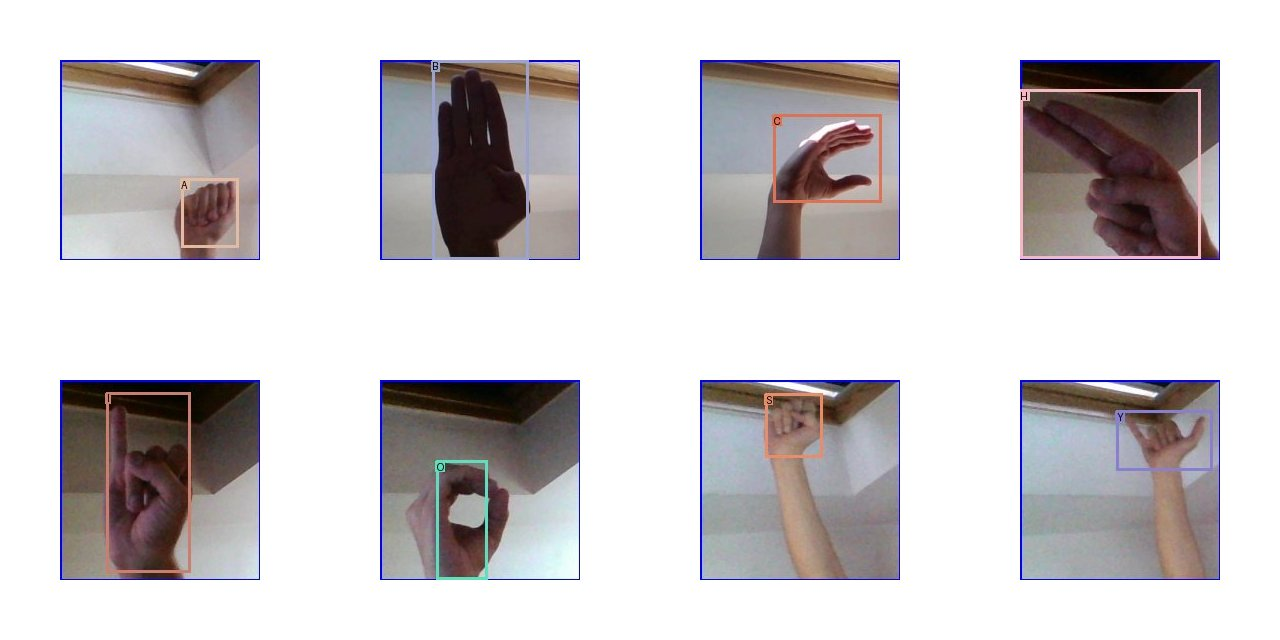

galerie : val


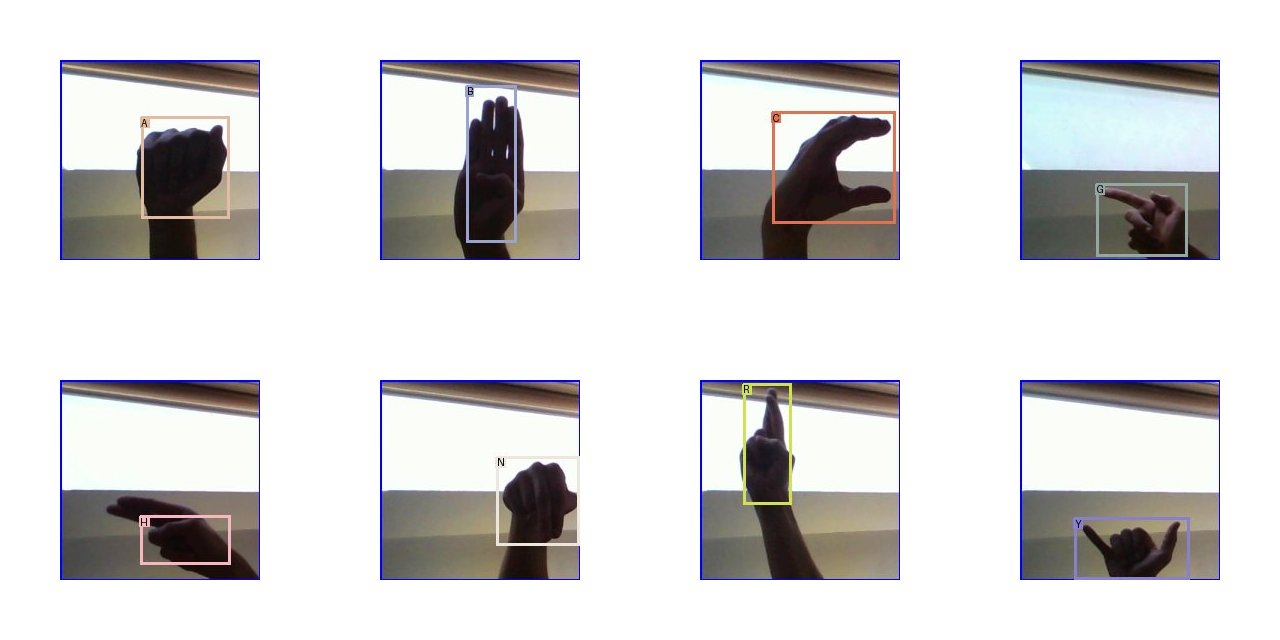

galerie : classes


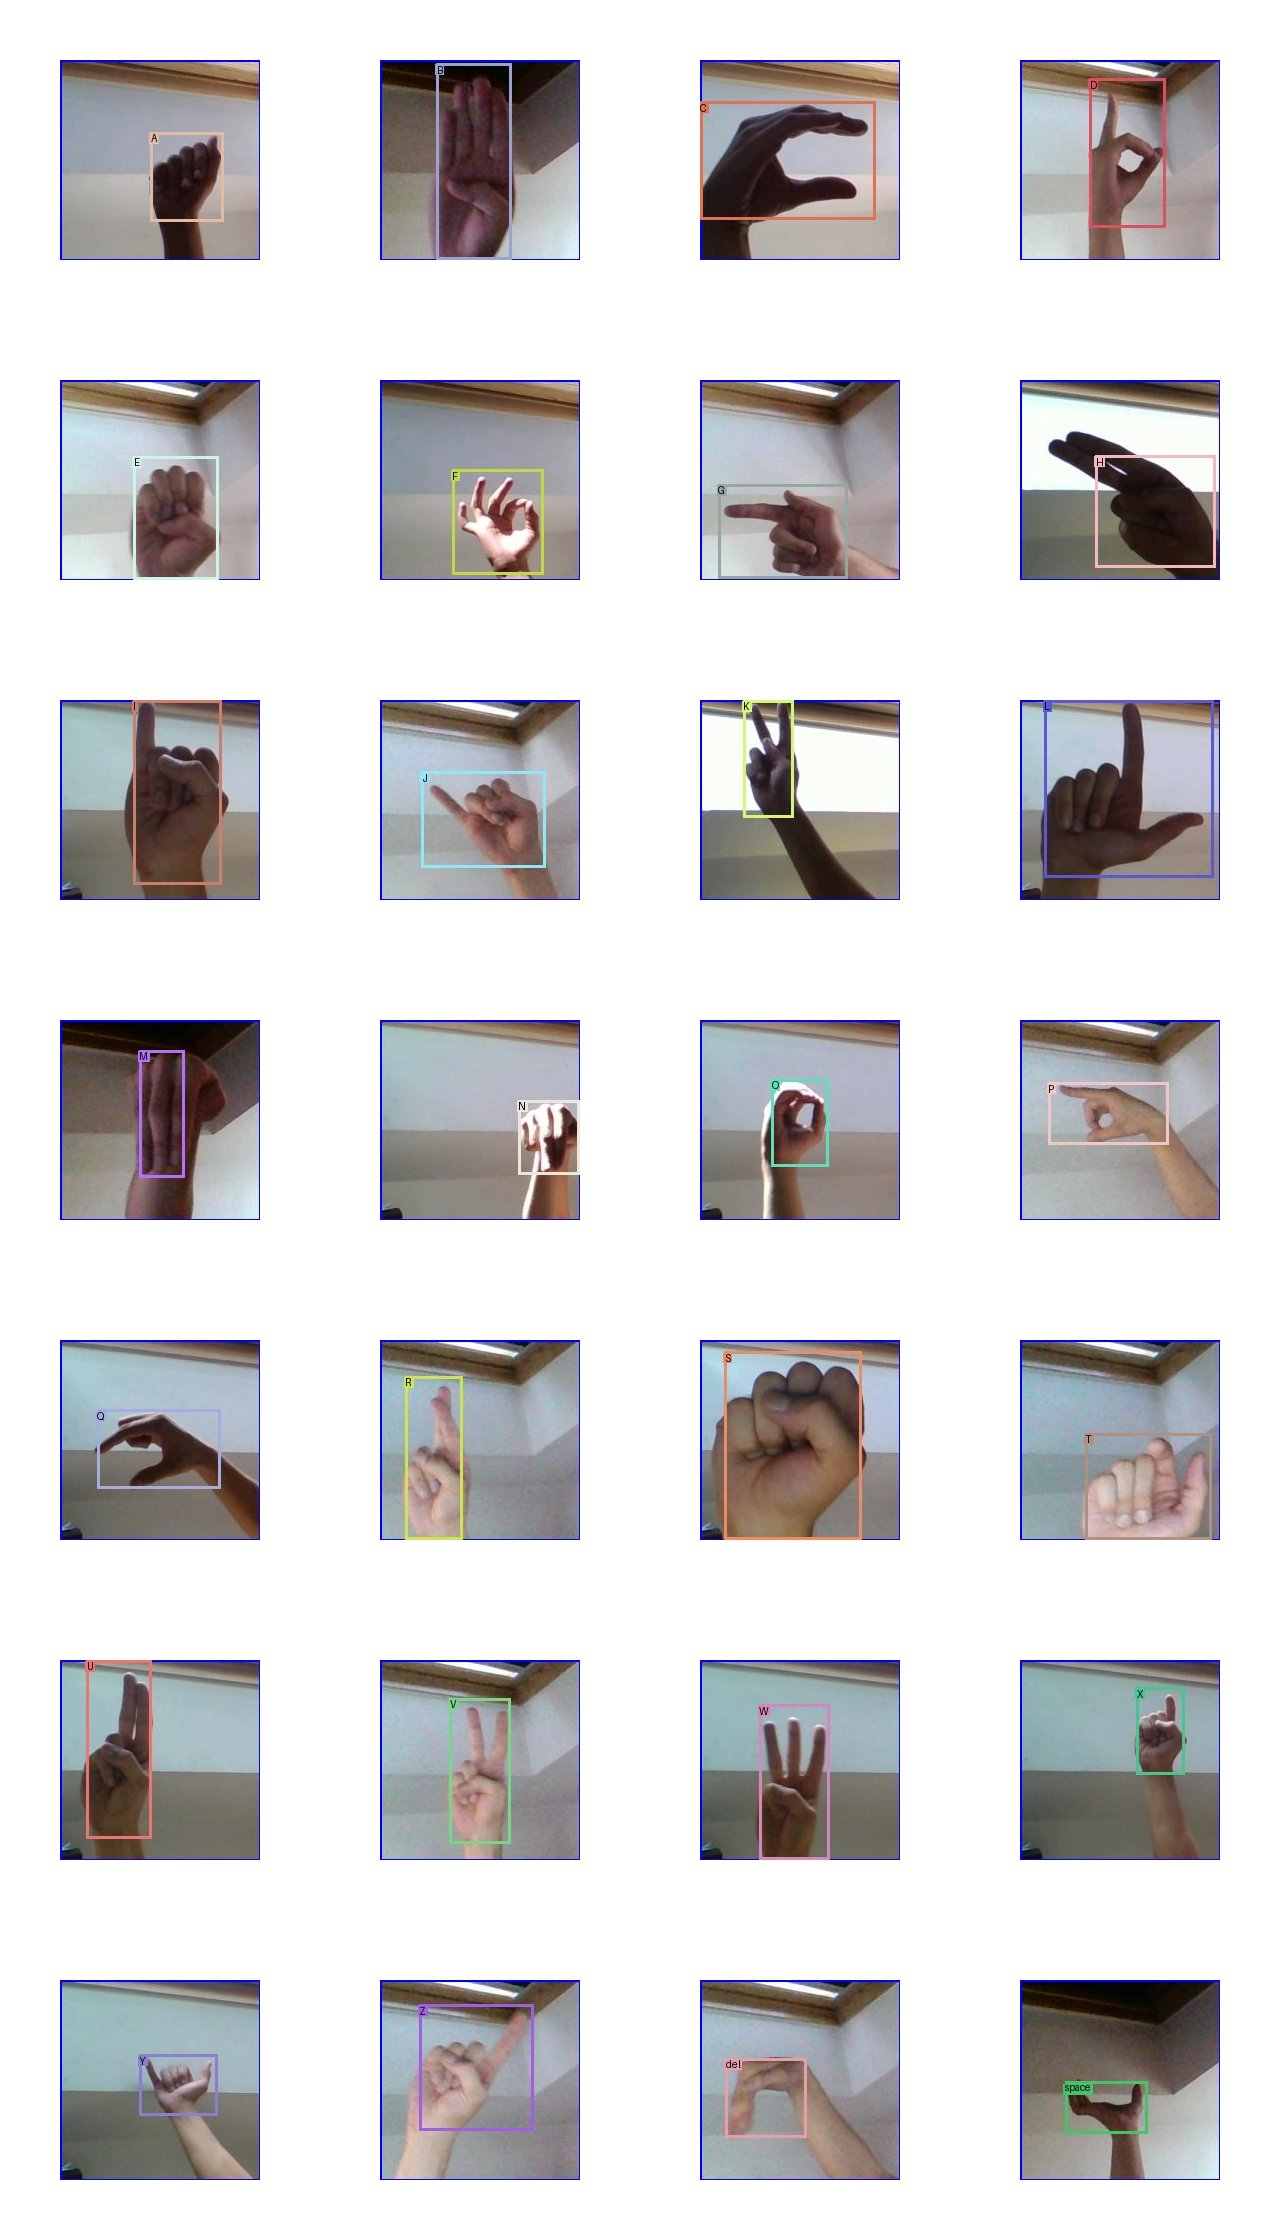

In [4]:
from yolo.data import datasets as D

rows = ["| classe | VOC | COCO |", "|---|---|---|"]
for c in D.DATASETS[DATASET].classes:
    m = [c if DATASET == f else D.MAPPINGS.get((DATASET, f), {}).get(c, "—")
         for f in ("voc", "coco")]
    rows.append(f"| {c} | {m[0]} | {m[1]} |")
display(Markdown("\n".join(rows)))
for g, sheet in STATS.get("galerie", {}).get("planches", {}).items():
    if g != "suspectes":
        print(f"galerie : {g}")
        display(Img(filename=str(Path(OUT, sheet))))

## Comptes et classes (T16.5)

Comptes par split (annotations, split entier), face aux effectifs officiels de la
fiche ; objets par classe et co-occurrence.

| partie | images | objets | difficult | images vides | objets/image (méd. / max) | petits < 32² à 416×416 | plus petits qu'une cellule | cibles perdues | images > 256 / > 1 024 |
|---|---|---|---|---|---|---|---|---|---|
| train | 69 984 | 67 434 | 0 | 2 550 | 1 / 1 | 0,0 % | 13x13 0,0 % · 26x26 0,0 % | 0,00 % | 0 / 0 |
| val | 6 538 | 6 088 | 0 | 450 | 1 / 1 | 0,0 % | 13x13 0,0 % · 26x26 0,0 % | 0,00 % | 0 / 0 |
| ensemble | 76 522 | 73 522 | 0 | 3 000 | 1 / 1 | 0,0 % | 13x13 0,0 % · 26x26 0,0 % | 0,00 % | 0 / 0 |

train : 69984 images, 67434 objets ; officiel — / — : ok
val : 6538 images, 6088 objets ; officiel — / — : ok


| classe | train : objets (images) | val : objets (images) | côté médian (px, letterbox) | petits |
|---|---|---|---|---|
| A | 2 297 (2 297) | 196 (196) | 168 | 0 % |
| B | 2 239 (2 239) | 117 (117) | 186 | 0 % |
| C | 2 339 (2 339) | 352 (352) | 194 | 0 % |
| D | 2 545 (2 545) | 285 (285) | 214 | 0 % |
| E | 2 308 (2 308) | 152 (152) | 169 | 0 % |
| F | 2 541 (2 541) | 450 (450) | 260 | 0 % |
| G | 2 525 (2 525) | 320 (320) | 195 | 0 % |
| H | 2 539 (2 539) | 201 (201) | 222 | 0 % |
| I | 2 473 (2 473) | 143 (143) | 209 | 0 % |
| J | 2 524 (2 524) | 301 (301) | 222 | 0 % |
| K | 2 500 (2 500) | 313 (313) | 193 | 0 % |
| L | 2 511 (2 511) | 325 (325) | 252 | 0 % |
| M | 2 293 (2 293) | 113 (113) | 173 | 0 % |
| N | 1 921 (1 921) | 106 (106) | 169 | 0 % |
| O | 2 395 (2 395) | 278 (278) | 175 | 0 % |
| P | 2 400 (2 400) | 167 (167) | 207 | 0 % |
| Q | 2 376 (2 376) | 154 (154) | 201 | 0 % |
| R | 2 496 (2 496) | 252 (252) | 183 | 0 % |
| S | 2 514 (2 514) | 314 (314) | 161 | 0 % |
| T | 2 480 (2 480) | 85 (85) | 202 | 0 % |
| U | 2 520 (2 520) | 194 (194) | 158 | 0 % |
| V | 2 529 (2 529) | 261 (261) | 178 | 0 % |
| W | 2 458 (2 458) | 273 (273) | 196 | 0 % |
| X | 2 479 (2 479) | 78 (78) | 191 | 0 % |
| Y | 2 507 (2 507) | 192 (192) | 192 | 0 % |
| Z | 2 468 (2 468) | 137 (137) | 206 | 0 % |
| del | 2 246 (2 246) | 137 (137) | 152 | 0 % |
| space | 2 011 (2 011) | 192 (192) | 150 | 0 % |

Rapport classe la plus / la moins fréquente : 1.

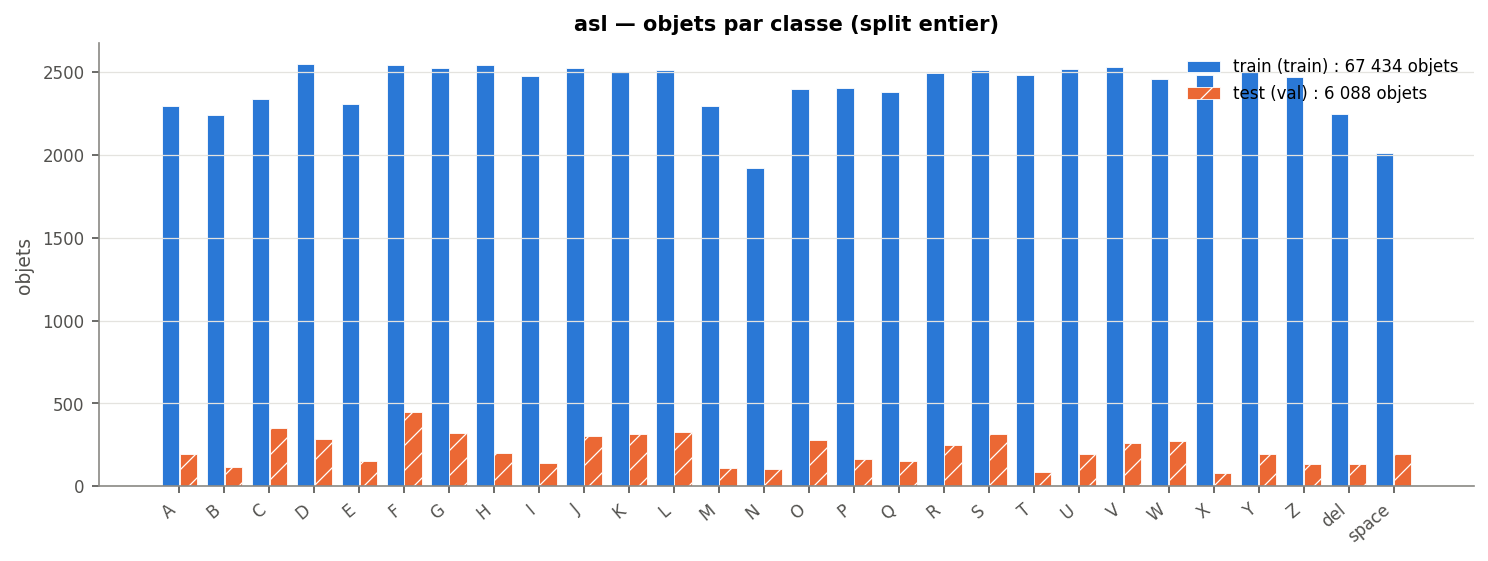

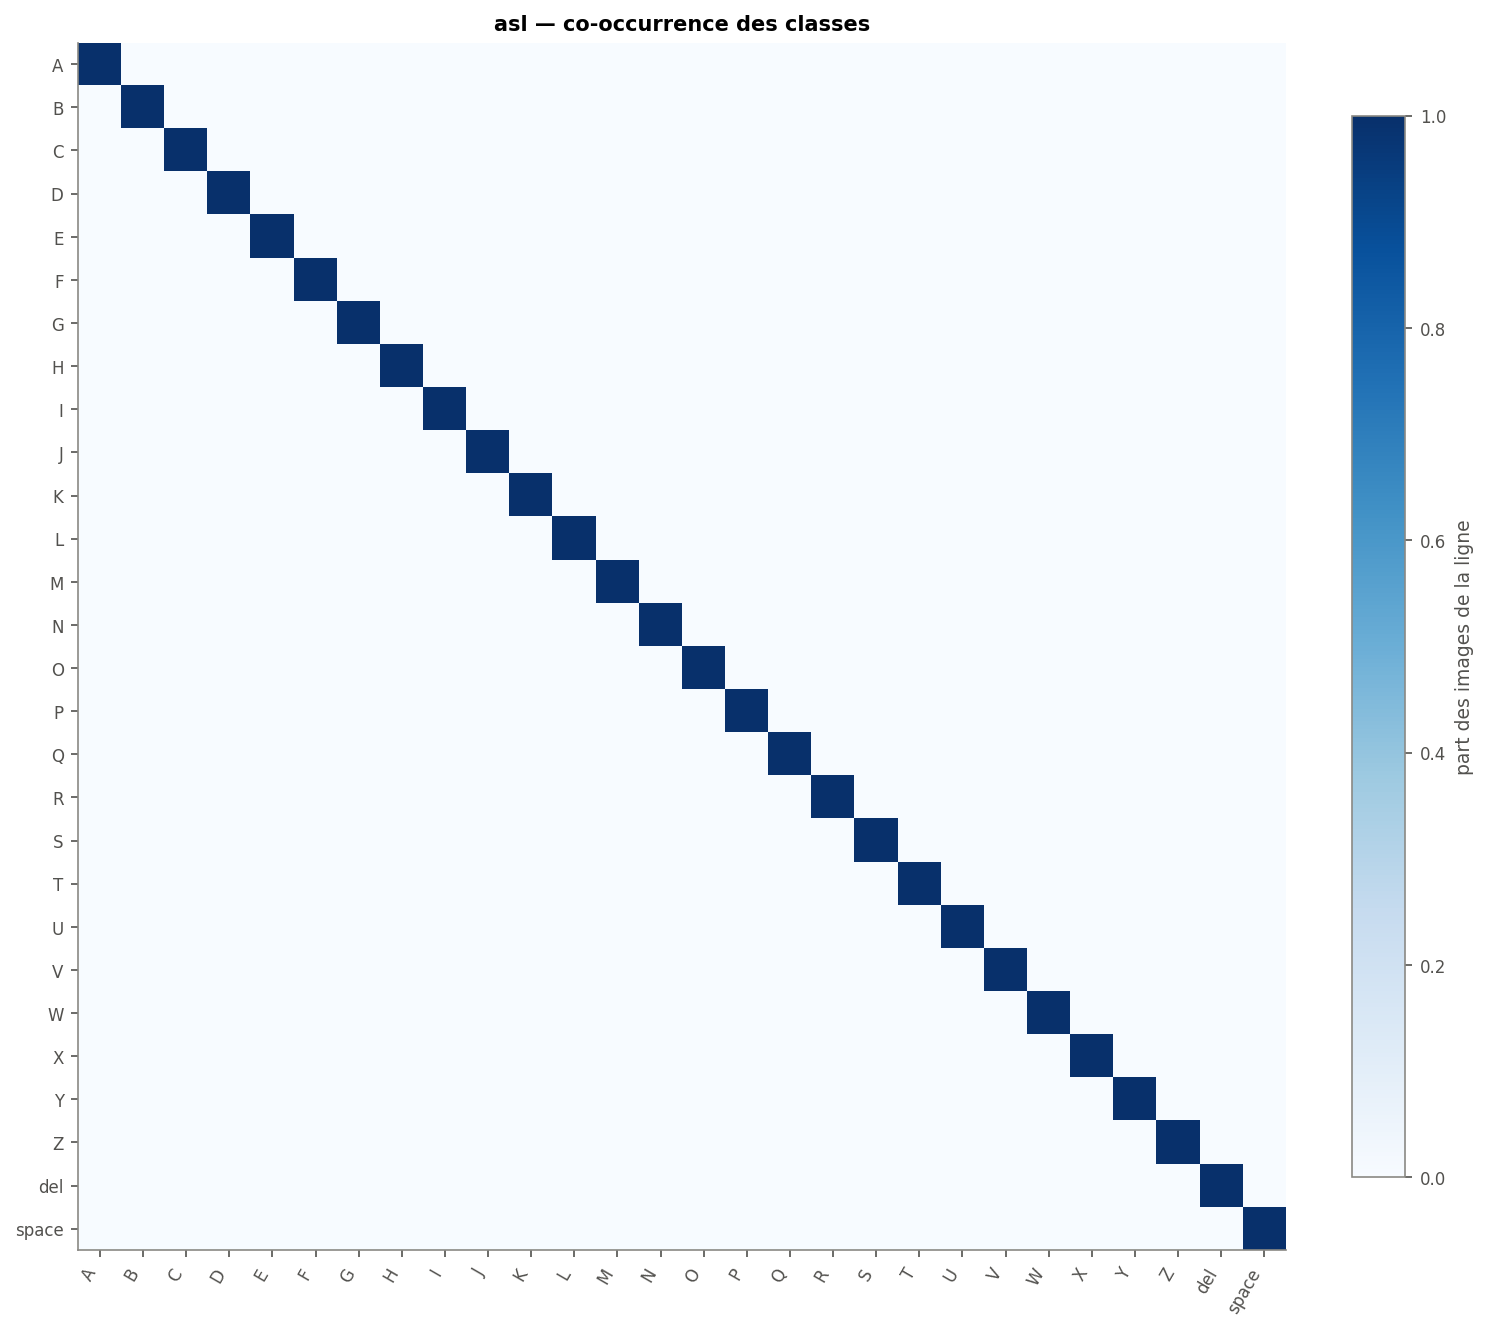

In [5]:
table(DS.md_synthese)
chk = DS.check_official(STATS)
for sp, i, o, (a, b), ok in chk:
    print(f"{sp} : {i} images, {o} objets ; officiel {a or '—'} / {b or '—'} : "
          f"{'ok' if ok else 'écart (voir les notes de la fiche)'}")
table(DS.md_classes)
show("classes")
show("cooccurrence")

## Géométrie des boîtes (T16.6)

Tailles en pixels d'origine et d'entrée (letterbox et stretch à `SIZE`), catégories
COCO avant et après redimensionnement, part des objets plus petits qu'une cellule de
chaque tête, centres des boîtes.

| repère | petits | moyens | grands | côté médian (px) | plus petits qu'une cellule | hauteur < 8 px |
|---|---|---|---|---|---|---|
| image d'origine | 0,2 % | 54,6 % | 45,3 % | 93 | — | — |
| letterbox 416×416 | 0,0 % | 1,1 % | 98,9 % | 193 | 13x13 0,0 % · 26x26 0,0 % | 0,0 % |
| stretch 416×416 | 0,0 % | 1,1 % | 98,9 % | 193 | 13x13 0,0 % · 26x26 0,0 % | 0,0 % |

73 522 objets non-difficult ; pas des têtes : 13x13 → 32 px, 26x26 → 16 px.

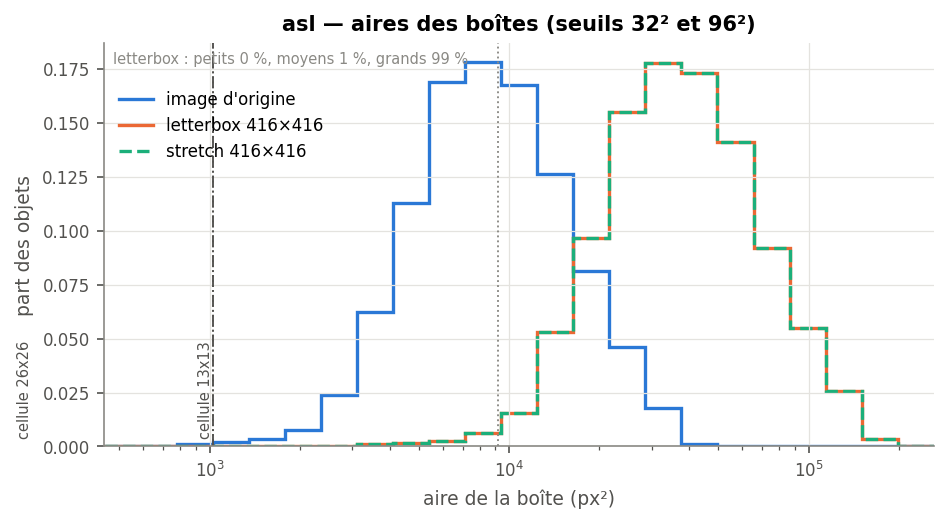

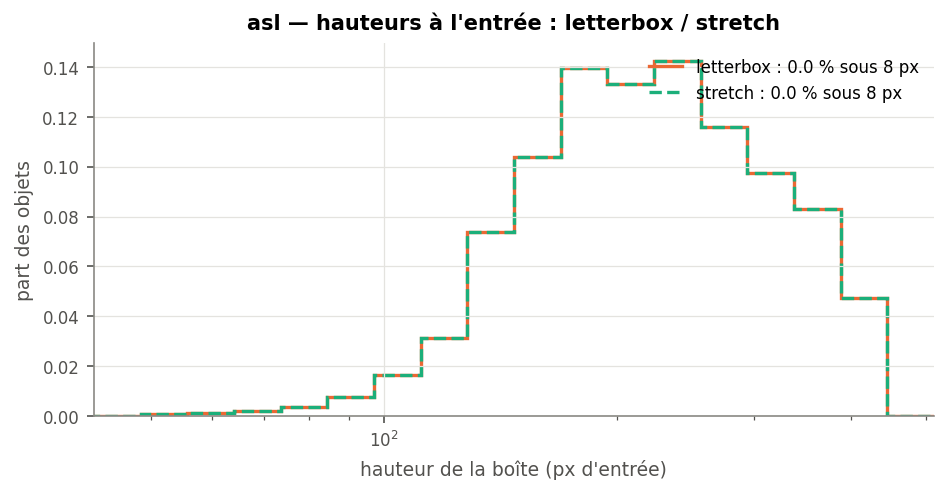

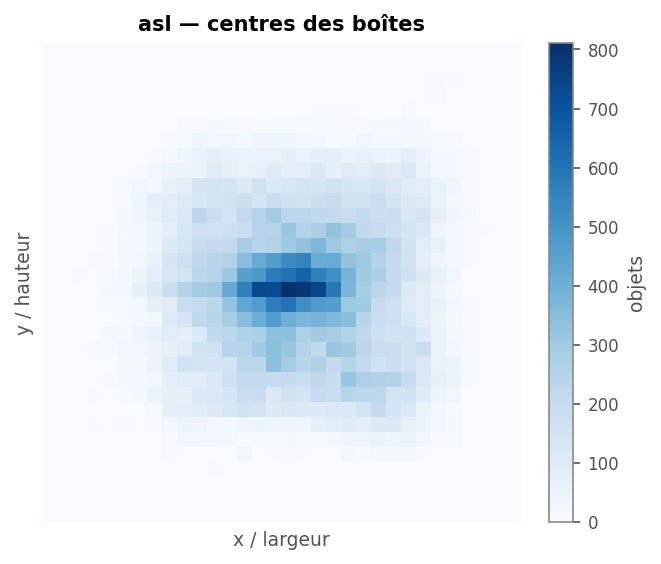

In [6]:
table(DS.md_geometrie)
show("tailles")
show("letterbox_stretch")
show("centres")

## Densité et collisions (T16.7)

Objets par image face aux 256 emplacements de `yolo_post` ; cibles perdues quand deux
objets tombent sur la même cellule et la même ancre (`build_targets`, ancres de `NET`).

| partie | objets/image moy. | méd. | max | > 256 / > 1 024 | cibles perdues | par tête (perdues / objets) | images touchées |
|---|---|---|---|---|---|---|---|
| train | 1,0 | 1 | 1 | 0 / 0 | 0 / 67 434 (0,00 %) | 13x13 : 0 / 28 845 · 26x26 : 0 / 38 589 | 0 |
| val | 0,9 | 1 | 1 | 0 / 0 | 0 / 6 088 (0,00 %) | 13x13 : 0 / 2 845 · 26x26 : 0 / 3 243 | 0 |
| ensemble | 1,0 | 1 | 1 | 0 / 0 | 0 / 73 522 (0,00 %) | 13x13 : 0 / 31 690 · 26x26 : 0 / 41 832 | 0 |

Ancres de `build/m11/cfg/tiny-yolov3-asl.cfg` ; objets non-difficult, comme à l'entraînement.

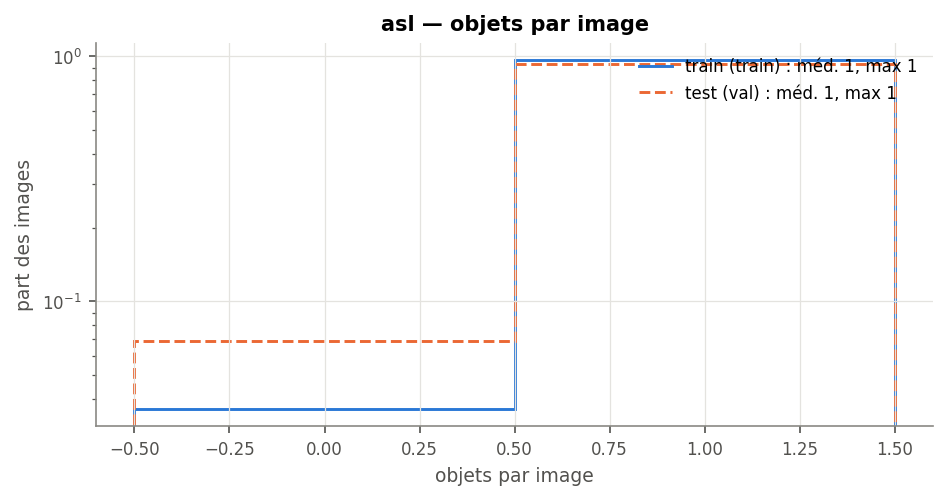

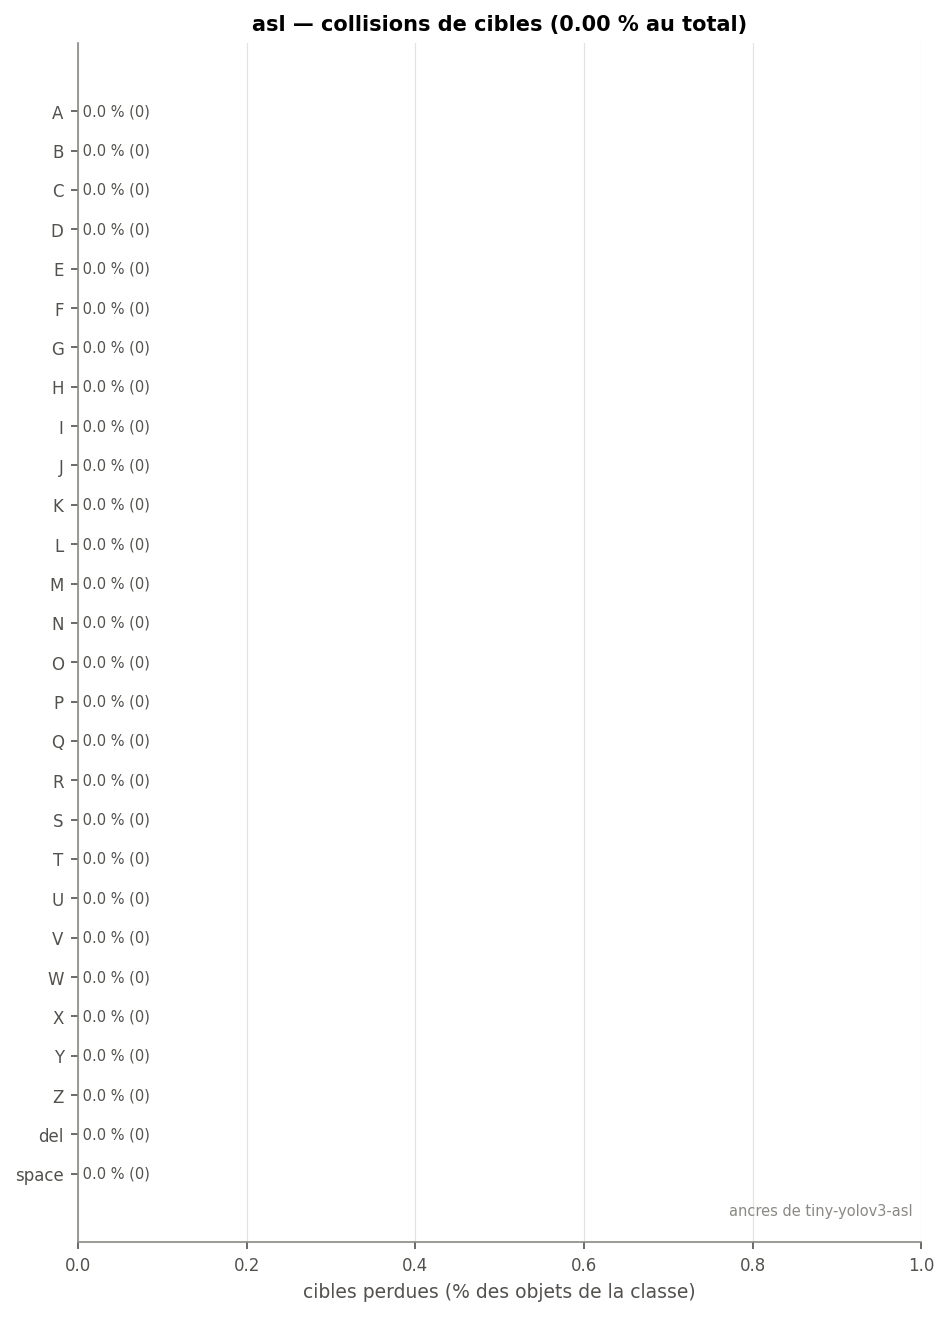

In [7]:
table(DS.md_densite)
show("densite")
show("collisions")

## Images (T16.8)

Résolutions sur le split entier (annotations) ; canaux, intensités et luminance sur
`SAMPLE` images par partie, face à VOC2007 test (échelles INT8 de M4).

| partie | résolutions (3 premières) | distinctes | pixels sur | canaux | moyenne par canal | écart type par canal | luminance moy. | niveaux 8 bits → INT8 |
|---|---|---|---|---|---|---|---|---|
| train | 200×200 (69 984) | 1 | 200 images | 3 | 131,6 / 125,7 / 130,2 | 51,1 / 59,1 / 62,4 | 127,9 | 255 → 128 |
| val | 200×200 (6 538) | 1 | 200 images | 3 | 146,6 / 143,1 / 144,0 | 83,4 / 88,6 / 85,9 | 144,3 | 255 → 128 |
| ensemble | 200×200 (76 522) | 1 | 200 images | 3 | 135,0 / 130,6 / 134,9 | 54,6 / 62,2 / 64,3 | 132,4 | 255 → 128 |

Référence VOC2007 test (200 images, graine 0) : luminance moyenne 107,7, moyenne par canal 112,1 / 107,1 / 98,5.

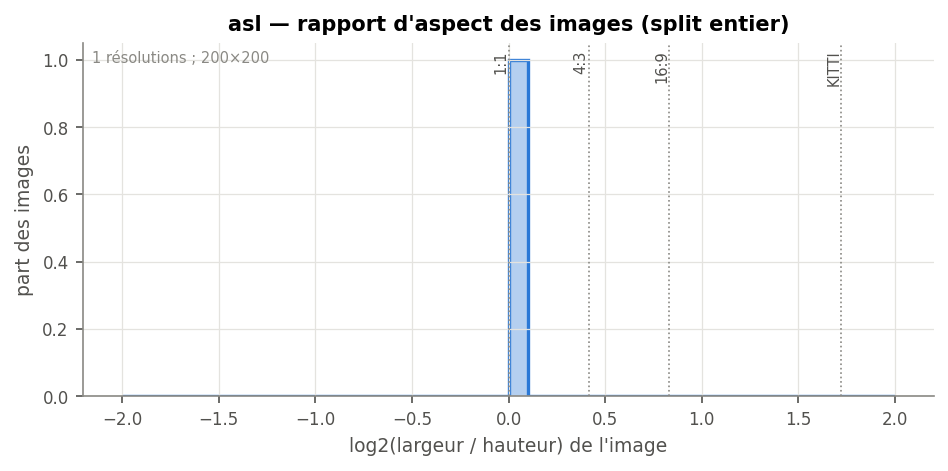

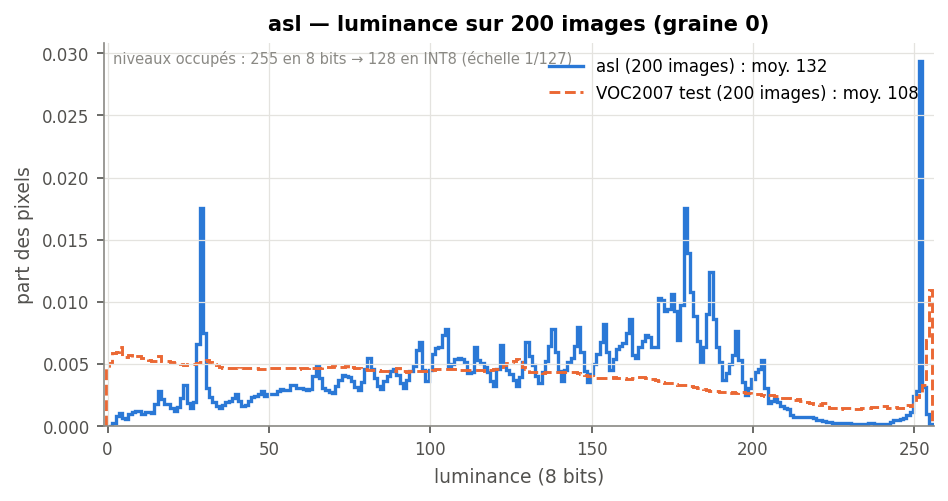

In [8]:
table(DS.md_images)
show("resolutions")
show("intensites")

## Ancres (T16.9)

Boîtes du groupe train en pixels d'entrée letterbox, ancres de la cfg, de VOC, de
COCO et du k-means (`tools/kmeans_anchors.py`, mêmes `--size` et `--seed`).

| ancres | w,h (px à 416×416) | IoU moyenne |
|---|---|---|
| VOC (tiny-yolov2-voc) | `35,38  109,141  212,364  301,164  532,337` | 0,6373 |
| VOC (tiny-yolov3-voc) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0,6152 |
| COCO (tiny-yolov3-coco) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0,6152 |
| cfg du jeu (tiny-yolov3-asl) | `99,163  191,152  127,245  246,224  171,347  310,339` | 0,7677 |
| k-means k = 5 (graine 0) | `151,144  105,218  233,201  159,321  297,329` | 0,7512 |
| k-means k = 6 (graine 0) | `99,163  191,152  127,245  246,224  171,347  310,339` | 0,7677 |

67 434 boîtes non-difficult du groupe train, letterbox 416×416.

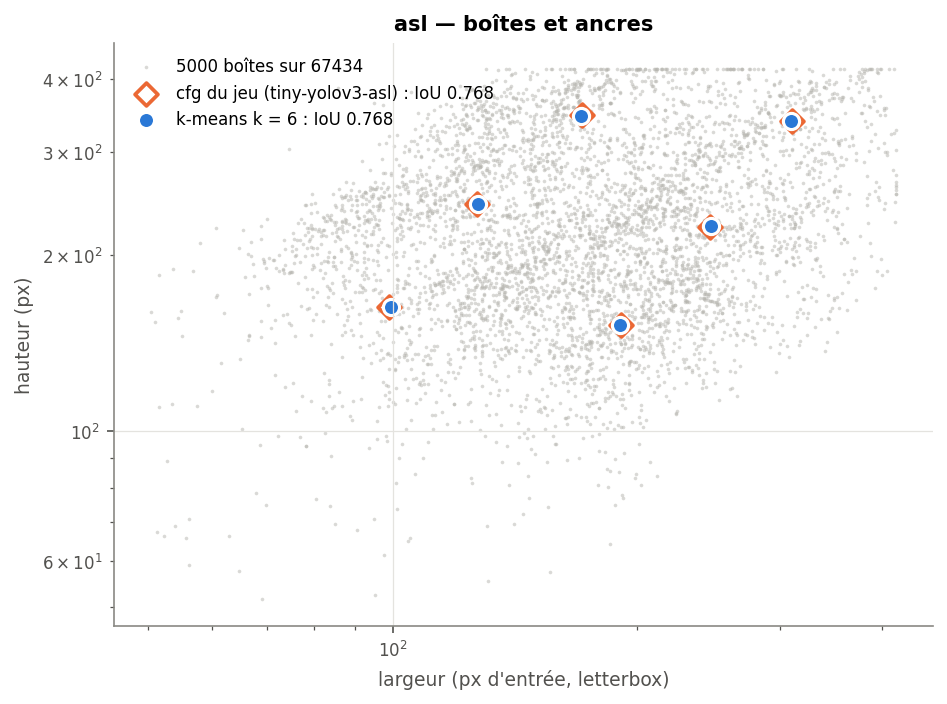

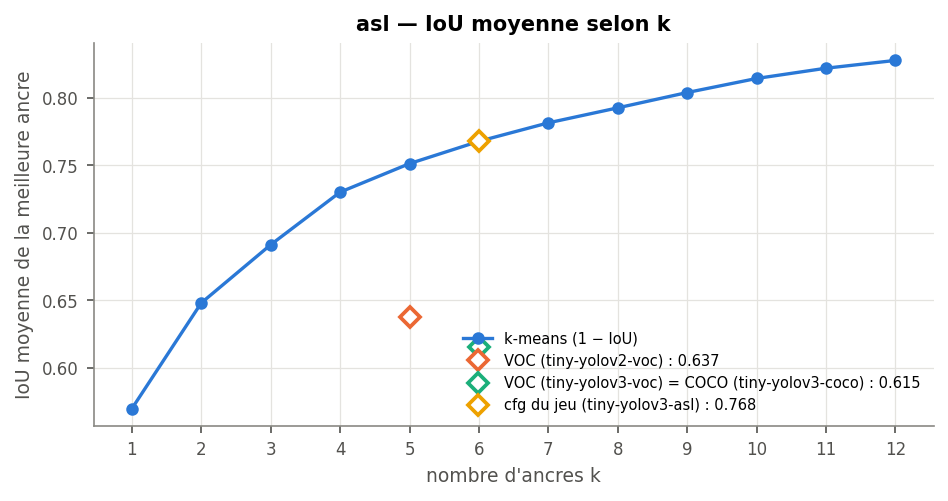

In [9]:
table(DS.md_ancres)
show("ancres")
show("ancres_k")

## Qualité des annotations (T16.10)

Boîtes retirées ou rognées par le chargeur, dégénérées, doublons, régions retirées ;
l'analyse signale, elle ne corrige pas (une correction passe par M11).

In [10]:
table(DS.md_qualite)
sus = DS.whole(STATS).get("qualite", {}).get("suspects", [])
for d in sus:
    print(f"{d['id']} : score {d['score']} (retirées {d['retirées']}, rognées "
          f"{d['rognées']}, dégénérées {d['dégénérées']}, doublons {d['doublons']})")
sheet = STATS.get("galerie", {}).get("planches", {}).get("suspectes")
if sheet:
    display(Img(filename=str(Path(OUT, sheet))))

| partie | retirées (make_sample) | rognées | côté < 2 px (orig. / entrée) | doublons (IoU > 0,95) | régions retirées par le chargeur |
|---|---|---|---|---|---|
| train | — | 0 | 0 / 0 | 0 | — |
| val | — | 0 | 0 / 0 | 0 | — |
| ensemble | — | 0 | 0 / 0 | 0 | — |

## Écart entre splits et couverture hors domaine (T16.11)

Distance en variation totale entre train et test, par grandeur ; part des objets qui
ont une classe VOC ou COCO (ce qu'évaluent les notebooks hors domaine de T14.5).

| grandeur (train ↔ test) | variation totale |
|---|---|
| classes | 0,170 |
| area_in | 0,133 |
| w_in | 0,100 |
| h_in | 0,136 |
| aspect | 0,107 |
| per_image | 0,032 |

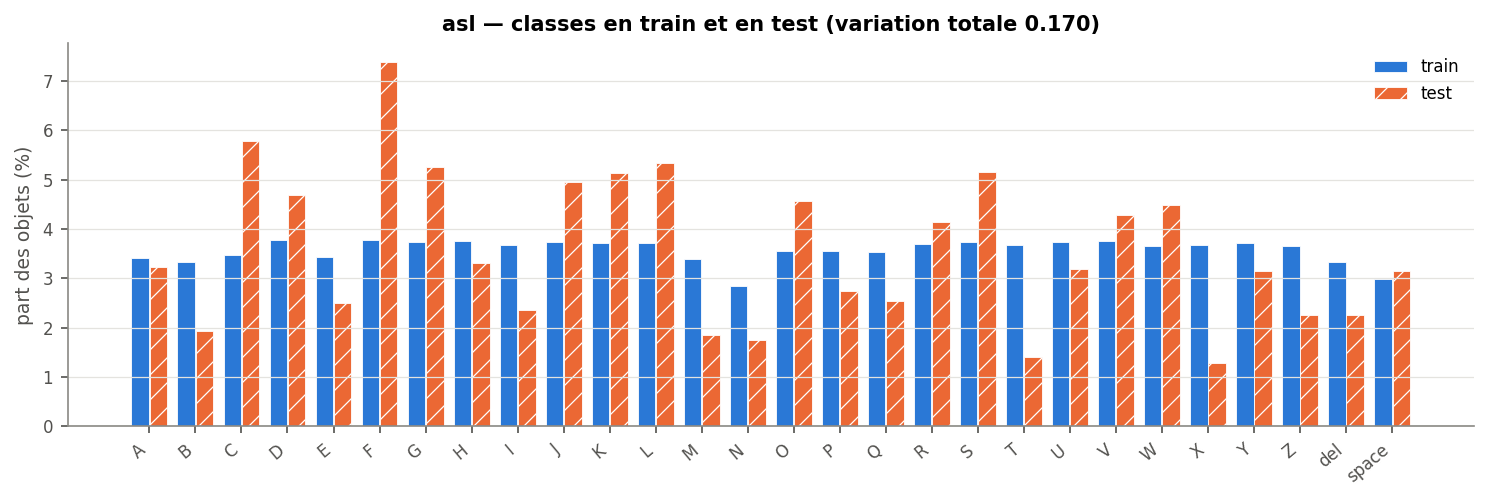

In [11]:
table(DS.md_ecart)
show("ecart")

## Question propre au jeu

How much of the input does the hand cover, and which classes lose the most images to the pseudo-box step? (renvoi : T21.1)

In [12]:
import json
from collections import Counter
from pathlib import Path
from yolo.data.datasets import DATA_DIR
g = DS.whole(STATS)["geometrie"]
mode = STATS["params"]["resize"]
print(f"median hand side: {g['orig']['median_side']:.0f} px of 200, "
      f"{g[mode]['median_side']:.0f} px at the {g['size'][1]}×{g['size'][0]} input")
rej = Path(DATA_ROOT or DATA_DIR / "asl") / "rejected.json"
if rej.exists():
    lost = Counter(r["class"] for r in json.loads(rej.read_text()))
    print(f"letter images left out (no hand found): {sum(lost.values())}; most: "
          + ", ".join(f"{c} {n}" for c, n in lost.most_common(8)))
display(Markdown(DS.md_par_classe(STATS)))

median hand side: 93 px of 200, 193 px at the 416×416 input
letter images left out (no hand found): 10481; most: N 974, space 797, B 644, del 617, M 594, E 541, A 508, Q 470


| classe | objets (test, non-difficult) | part | côté médian (px) | petits | cibles perdues |
|---|---|---|---|---|---|
| A | 196 | 3,2 % | 189 | 0 % | 0,00 % |
| B | 117 | 1,9 % | 213 | 0 % | 0,00 % |
| C | 352 | 5,8 % | 255 | 0 % | 0,00 % |
| D | 285 | 4,7 % | 236 | 0 % | 0,00 % |
| E | 152 | 2,5 % | 170 | 0 % | 0,00 % |
| F | 450 | 7,4 % | 266 | 0 % | 0,00 % |
| G | 320 | 5,3 % | 185 | 0 % | 0,00 % |
| H | 201 | 3,3 % | 220 | 0 % | 0,00 % |
| I | 143 | 2,3 % | 226 | 0 % | 0,00 % |
| J | 301 | 4,9 % | 234 | 0 % | 0,00 % |
| K | 313 | 5,1 % | 178 | 0 % | 0,00 % |
| L | 325 | 5,3 % | 234 | 0 % | 0,00 % |
| M | 113 | 1,9 % | 182 | 0 % | 0,00 % |
| N | 106 | 1,7 % | 179 | 0 % | 0,00 % |
| O | 278 | 4,6 % | 219 | 0 % | 0,00 % |
| P | 167 | 2,7 % | 202 | 0 % | 0,00 % |
| Q | 154 | 2,5 % | 199 | 0 % | 0,00 % |
| R | 252 | 4,1 % | 163 | 0 % | 0,00 % |
| S | 314 | 5,2 % | 149 | 0 % | 0,00 % |
| T | 85 | 1,4 % | 190 | 0 % | 0,00 % |
| U | 194 | 3,2 % | 165 | 0 % | 0,00 % |
| V | 261 | 4,3 % | 168 | 0 % | 0,00 % |
| W | 273 | 4,5 % | 164 | 0 % | 0,00 % |
| X | 78 | 1,3 % | 215 | 0 % | 0,00 % |
| Y | 192 | 3,2 % | 179 | 0 % | 0,00 % |
| Z | 137 | 2,3 % | 179 | 0 % | 0,00 % |
| del | 137 | 2,3 % | 143 | 0 % | 0,00 % |
| space | 192 | 3,2 % | 189 | 0 % | 0,00 % |

## Résumé

In [13]:
table(DS.md_synthese)
print(f"sorties : {OUT}/ (stats.json, stats.md, figures/, galerie/) ; "
      f"révision {TRACE['rev']}")
print("commandes équivalentes :")
for c in C.HISTORY:
    print("  " + c)

| partie | images | objets | difficult | images vides | objets/image (méd. / max) | petits < 32² à 416×416 | plus petits qu'une cellule | cibles perdues | images > 256 / > 1 024 |
|---|---|---|---|---|---|---|---|---|---|
| train | 69 984 | 67 434 | 0 | 2 550 | 1 / 1 | 0,0 % | 13x13 0,0 % · 26x26 0,0 % | 0,00 % | 0 / 0 |
| val | 6 538 | 6 088 | 0 | 450 | 1 / 1 | 0,0 % | 13x13 0,0 % · 26x26 0,0 % | 0,00 % | 0 / 0 |
| ensemble | 76 522 | 73 522 | 0 | 3 000 | 1 / 1 | 0,0 % | 13x13 0,0 % · 26x26 0,0 % | 0,00 % | 0 / 0 |

sorties : build/notebooks/asl/stats/ (stats.json, stats.md, figures/, galerie/) ; révision 3263136
commandes équivalentes :
  python tools/data_stats.py --dataset asl --size 416 --resize letterbox --net build/m11/cfg/tiny-yolov3-asl.cfg --sample 200 --gallery 8 --seed 0 --figures --out build/notebooks/asl/stats
